<a href="https://colab.research.google.com/github/tselane2110/Urdu-BinarySarcasmDetection/blob/main/TF_IDF_logisticRegressionModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Cloning into Git Repo

In [1]:
# cloning into Git Repo
!git clone https://github.com/tselane2110/NaturalLanguageProcessing

fatal: destination path 'NaturalLanguageProcessing' already exists and is not an empty directory.


In [2]:

%cd /content/NaturalLanguageProcessing

/content/NaturalLanguageProcessing


In [3]:
%ls

NaturalLanguageProcessing/  TF_IDF_logisticRegressionModel.ipynb
projectGuidelines.pdf       urdu_sarcastic_dataset.csv
README.md


## 1. Data Analysis and Preprocessing

In [4]:
import re
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_colwidth', None)   # show full column width
df = pd.read_csv('urdu_sarcastic_dataset.csv')
df.head()

,urdu_text,is_sarcastic,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,نہیں پائین 😎,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1.0,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.columns

Index(['urdu_text', 'is_sarcastic', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4',
       'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'],
      dtype='object')

### i. Not Including Unnecessary Columns

In [6]:
# not using the extra unimportant columns

df = df.iloc[:, :-6]
df.head(10)

,urdu_text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0.0
3,نہیں پائین 😎,0.0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1.0
5,قابل اعتبار ہی اکثر قاتل اعتبار ہوتے ہیں 💔🔥,1.0
6,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,0.0
7,حامد میر صاحب ویلڈن👏😊,0.0
8,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,1.0
9,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,1.0


In [7]:
# renaming the text columns
df = df.rename(columns={'urdu_text': 'text'})
df.head(2)

,text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0


### ii. Dropping NaN rows

In [8]:
# finding NaN rows

df.isna().sum()

,0
text,105
is_sarcastic,56


In [9]:
# dropping all NaN rows

df = df.dropna()

In [10]:
df.head(2)

,text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0


### iii. Identifying Class Distribution

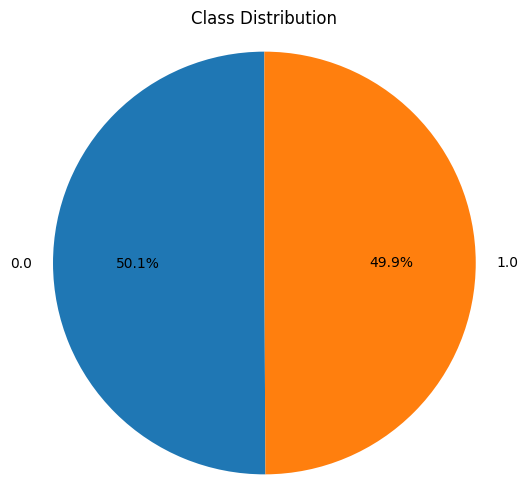

is_sarcastic
0.0    9993
1.0    9962
Name: count, dtype: int64


In [11]:
import matplotlib.pyplot as plt

# Assuming y is your target column (pandas Series or array)
counts = df['is_sarcastic'].value_counts()

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Class Distribution')
plt.axis('equal')
plt.show()

# Print counts too
print(counts)

### iv. Converting DataType from Float to Int of `is_sarcastic` Column

In [12]:
# converting the datatype of is_sarcastic from float to int

df['is_sarcastic'] = df['is_sarcastic'].astype(int)
df.head(2)

,text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1


### v. Detecting and Analyzing Hashtag Content

In [13]:
import re
from collections import Counter

# extract all hashtags (lowercased) across all rows
hashtags = df['text'].str.findall(r'#(\w+)', flags=re.IGNORECASE)

# flatten and count
counter = Counter(
    tag.lower()
    for tags in hashtags
    for tag in tags
)

hashtag_counts = dict(counter)

In [14]:
len(hashtag_counts)

551

In [15]:
hashtag_df = pd.DataFrame(
    hashtag_counts.items(),
    columns=['hashtag', 'count']
)

In [16]:
hashtag_df = hashtag_df.sort_values('count', ascending=False).reset_index(drop=True)

In [17]:
hashtag_df.head(551)

,hashtag,count
0,sarcasm,391
1,طنز,163
2,sarcastic,57
3,آئےناں_کنٹینرتے,31
4,مزاح,22
...,...,...
546,tmc,1
547,bjp,1
548,lighthearted,1
549,خوش_مزاج_مولوی,1


### vi. Text Cleaning

* Removed the following content:

  * URLs
  * @mentions
  * Hashtag contents that could leak the target label, for example #sarcasm, #sarcastic, #طنز etc. These were selected after carefully analyzing all hashtags that were present in the originally given dataset.

* Added \<EMPHASIS\>\<\EMPHASIS\> around the bold text
* Normalized Whitespaces
* Used `wordsegment` library to segment out the joint english words like goodmorningpakistan or HelloWorld would be converted to "good morning pakistan" and "hello world"
* Demojized emojis continue to keep the underscore in their name_tag


In [18]:
!pip install emoji

In [19]:
!pip install wordsegment

#### a. Helper Functions

In [20]:
import re
import emoji
import pandas as pd
import string
import unicodedata
from wordsegment import load, segment

load() # Load the English dictionaries for segmentation

URL_PATTERN = re.compile(r'(?:https?://|www\.)[^\s]+(?<![.,;!?؟۔،\)"\'])', re.IGNORECASE)
MENTION_PATTERN = re.compile(r'@[A-Za-z0-9_]+')
LEAKY = [r"sarcasm\w*", r"sarcastic\w*", r"beingsarcastic",
         r"satire\w*", r"racistjokes",
         r"طنزومزاح", r"طنز"]                 # only standard forms now
SARCASM_PATTERN = re.compile(r"#?(?:" + "|".join(LEAKY) + r")(?!\w)", re.IGNORECASE)
UNICODE_BOLD = re.compile(r'[\U0001D400-\U0001D7FF]+')

# Function to extract emojis into a new column and remove them from text
def extract_and_remove_emojis(text):
    text = str(text)
    # Find all emojis in the text
    found_emojis = "".join([char for char in text if char in emoji.EMOJI_DATA])
    # Remove emojis from the text
    cleaned_text = "".join(
        [char for char in text if char not in emoji.EMOJI_DATA]
    )
    return cleaned_text, found_emojis

# Function to process the hashtags with important content
def process_advanced_hashtags(text):
    # Find all hashtags
    hashtags = re.findall(r'#\w+', text)

    for tag in hashtags:
        clean_tag = tag.replace('#', '')

        # Check if it contains Urdu characters
        if re.search(r'[\u0600-\u06FF]', clean_tag):
            # It's Urdu: just remove the hash, leave it joined
            text = text.replace(tag, clean_tag)
        else:
            # It's English/Roman: Segment it using the library
            # segment() handles both CamelCase and all-lowercase brilliantly
            split_words = " ".join(segment(clean_tag))
            text = text.replace(tag, split_words)

    return text

def handle_bold_text(text):

    # 1. *word* or **word** → <EMPHASIS>word</EMPHASIS>
    text = re.sub(r'\*{1,2}([^*]+?)\*{1,2}', r'<EMPHASIS>\1</EMPHASIS>', text)

    # 2. Unicode bold runs → <EMPHASIS>...</EMPHASIS>
    text = UNICODE_BOLD.sub(lambda m: f"<EMPHASIS>{m.group(0)}</EMPHASIS>", text)

    return text

#### b. Text Preprocessing Pipeline

In [21]:
def text_preprocessing_pipeline(text):
    text = str(text)

    # normalizing arabic/urdu script
    text = unicodedata.normalize('NFKC', text)

    # adding <EMPHASIS></EMPHASIS> tags around bold words
    text = handle_bold_text(text)

    # Replacing URLs with the <URL> tags
    text = URL_PATTERN.sub('<URL>', text)

    # Removing all @mentions
    text = MENTION_PATTERN.sub('<USER>' , text)

    # Remove the terms that could risk leaking the target label
    text = SARCASM_PATTERN.sub("", text)

    # Preprocessing of the hashtags with the content we wanna keep
    text = process_advanced_hashtags(text)

    # replacing any remaining # symbols with whitespaces
    text = text.replace('#', '')

    # replacing all underscores with a white space
    text = text.replace('_', ' ')

    # Standardizing Urdu Punctuation to English equivalents
    text = text.replace('؟', '?').replace('۔', '.').replace('،', ',').replace('؛', ';').replace('٪', '%')

    # Remove hidden ZWNJ characters to prevent duplicate vocabulary tokens
    text = text.replace('\u200c', '')

    # Demojize Emojis INLINE
    # Converts 🙄 to "[rolling_eyes]" so the model reads it exactly where it occurred.
    text = emoji.demojize(text, delimiters=(" <", "> "))

    # converting all english text to lower-case
    text = text.lower()

    # Find all ?, ., ! marks
    found_punc = "".join(re.findall(r"[?.!]", text))

    # normalizing whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove all sorts of punctuation from the text
    # string.punctuation covers all standard symbols

    punct_to_remove = string.punctuation.replace("\\", "").replace("<", "").replace(">", "")

    translator = str.maketrans("", "", punct_to_remove)
    cleaned_text = text.translate(translator)

    return cleaned_text, found_punc

#### c. Function for One-Hot Encoding Each Column

In [22]:
from collections import Counter

def expand_element_counts(df, column_name):
    """
    Parses a column containing strings.
    - Preserves <tags> as whole unique elements (e.g., '<user_id>').
    - Treats all other non-space characters as individual elements.
    """
    def extract_and_tokenize(text):
        if pd.isna(text):
            return []

        # The change is here: [^<>\s] no longer has a '+' at the end.
        # This forces it to grab individual characters instead of chunks.
        return re.findall(r'<[^>]+>|[^<>\s]', str(text))

    # 1. Tokenize the string and count occurrences for each row
    counts_list = df[column_name].apply(lambda x: Counter(extract_and_tokenize(x))).tolist()

    # 2. Feed directly into a DataFrame constructor
    # 3. Fill missing elements with 0 and convert to integers, keeping original index
    counts_df = pd.DataFrame(counts_list, index=df.index).fillna(0).astype(int)

    # 4. Join the new columns back to the original DataFrame
    return pd.concat([df, counts_df], axis=1)

### vii. Emoji Count Analysis

In [23]:
df_emoji = df.copy()
df_emoji["text_no_emoji"], df_emoji["emojis"] = zip(*df_emoji["text"].apply(extract_and_remove_emojis))

In [24]:
df_emoji.columns

Index(['text', 'is_sarcastic', 'text_no_emoji', 'emojis'], dtype='object')

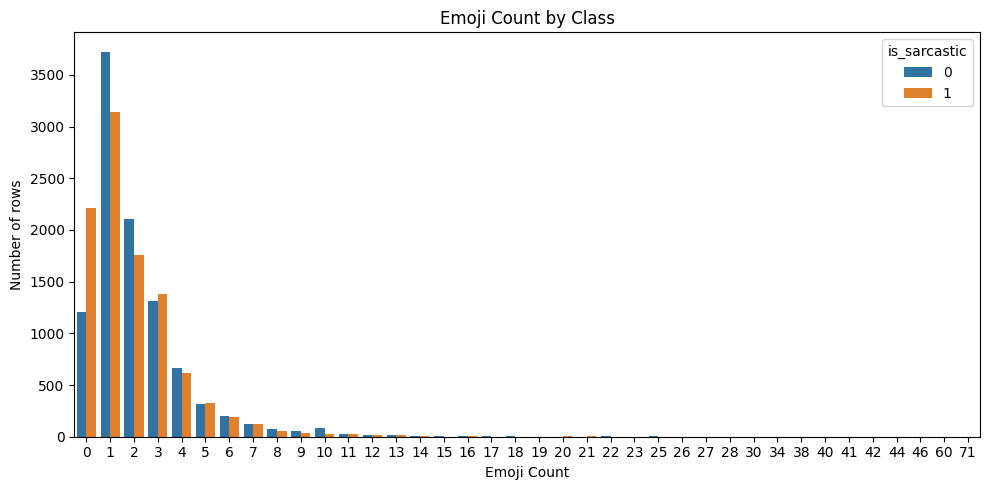

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# df_emoji has an emoji-only column, e.g. 'emojis'
df_emoji['emoji_count'] = df_emoji['emojis'].fillna('').astype(str).apply(len)

# plot
plt.figure(figsize=(10, 5))
sns.countplot(data=df_emoji, x='emoji_count', hue='is_sarcastic')
plt.title('Emoji Count by Class')
plt.xlabel('Emoji Count')
plt.ylabel('Number of rows')
plt.tight_layout()
plt.show()

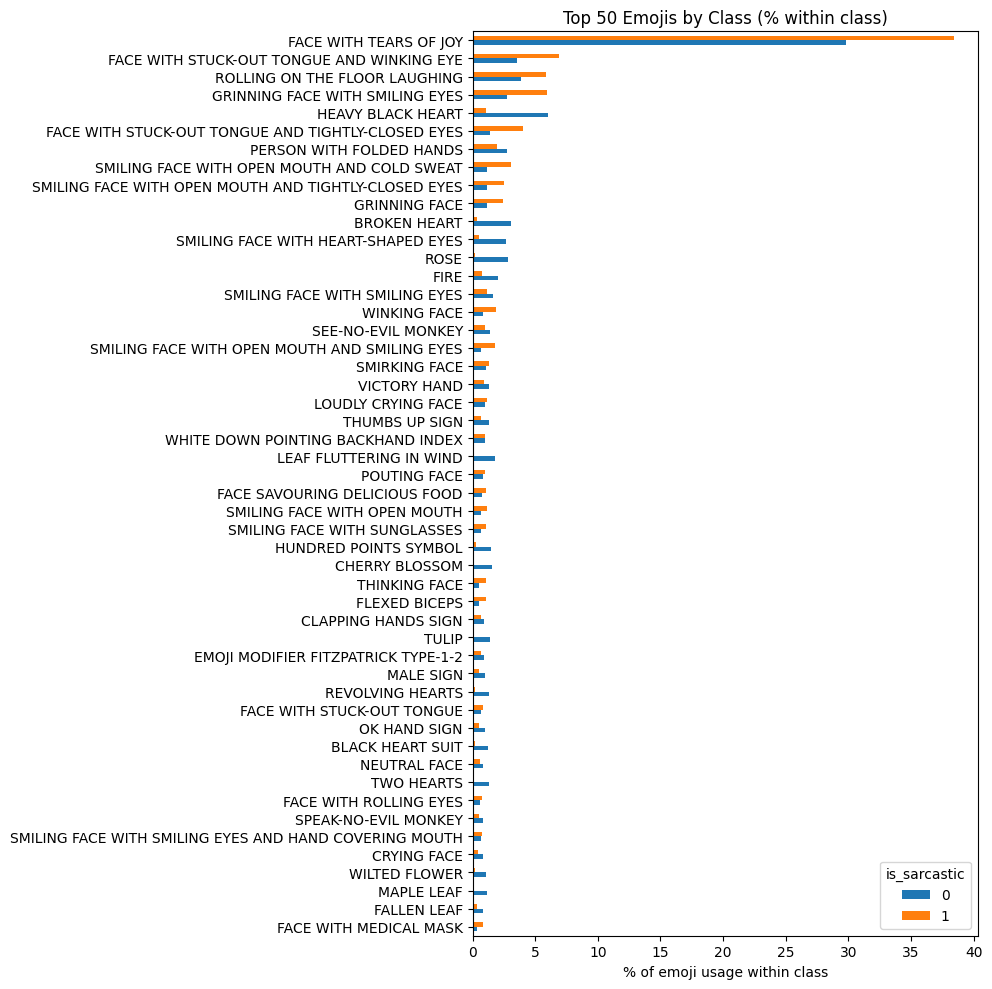

In [26]:
import matplotlib
matplotlib.rcdefaults()          # reset font config

import matplotlib.pyplot as plt
import pandas as pd
import unicodedata

# 1. Explode
exploded = df_emoji[['emojis', 'is_sarcastic']].copy()
exploded['emojis'] = exploded['emojis'].fillna('').astype(str)
exploded = exploded.assign(emoji=exploded['emojis'].apply(list)).explode('emoji')
exploded = exploded[exploded['emoji'].str.strip() != '']

# 2. Counts per class
counts = exploded.groupby(['emoji', 'is_sarcastic']).size().unstack(fill_value=0)

# 3. Top N by total
top_n = 50
counts['total'] = counts.sum(axis=1)
top = counts.sort_values('total', ascending=False).head(top_n).drop(columns='total')

# 4. Normalize within class
top_pct = top / top.sum(axis=0) * 100

# 5. Emoji -> Unicode name
def emoji_label(e):
    try:
        return unicodedata.name(e)
    except ValueError:
        return f'U+{ord(e):04X}'

top_pct.index = [emoji_label(e) for e in top_pct.index]

# 6. Plot
top_pct[::-1].plot(kind='barh', figsize=(10, 10))
plt.title(f'Top {top_n} Emojis by Class (% within class)')
plt.xlabel('% of emoji usage within class')
plt.tight_layout()
plt.show()

### viii. Dataset-1 (with individual emojis and punctuations as a separate features)

Contains the following columns:

* `is_sarcastic`
* `text` without emojis and punctuations
* `word_count` - added after preprocessing

And the following columns contain the count of each element in a row:

* `!`
* `?`
* `.`
* A separate column for each demojized emoji (**591 columns**)

In [27]:
df1 = df.copy()

# Apply Emoji extraction
df1["text_no_emoji"], df1["emojis"] = zip(*df1["text"].apply(extract_and_remove_emojis))

# Apply Punctuation extraction on the emoji-cleaned text (or original text)
df1["cleaned_text"], df1["punctuations"] = zip(
    *df1["text_no_emoji"].apply(text_preprocessing_pipeline)
)

# Clean up intermediate column if you want
df1 = df1.drop(columns=["text_no_emoji"])
# Dropping the uncleaned `text` column
df1.drop(columns='text', inplace=True)
# Renaming `cleaned_text` to `text`
df1 = df1.rename(columns={'cleaned_text': 'text'})
# output
df1.columns

Index(['is_sarcastic', 'emojis', 'text', 'punctuations'], dtype='object')

In [28]:
# Changes 🔥 from :fire: to <fire>
df1['demojized'] = df1['emojis'].apply(
    lambda x: emoji.demojize(x, delimiters=("<", ">")) if pd.notna(x) else x
)
df1.drop(columns=['emojis'], inplace = True)

In [29]:
df1 = expand_element_counts(df1, 'demojized')
df1 = expand_element_counts(df1, 'punctuations')
df1.drop(columns=['demojized', 'punctuations'], inplace = True)
df1.columns

Index(['is_sarcastic', 'text', '<rolling_on_the_floor_laughing>',
       '<face_with_tears_of_joy>', '<neutral_face>', '<folded_hands>',
       '<smiling_face_with_sunglasses>', '<beaming_face_with_smiling_eyes>',
       '<broken_heart>', '<fire>',
       ...
       '<person_running_medium-light_skin_tone>', '<sparkle>', '<brain>',
       '<ATM_sign>', '<coin>', '<money_bag>', '<white_cane>', '.', '?', '!'],
      dtype='object', length=596)

In [30]:
df1.columns.tolist()

['is_sarcastic',
 'text',
 '<rolling_on_the_floor_laughing>',
 '<face_with_tears_of_joy>',
 '<neutral_face>',
 '<folded_hands>',
 '<smiling_face_with_sunglasses>',
 '<beaming_face_with_smiling_eyes>',
 '<broken_heart>',
 '<fire>',
 '<maple_leaf>',
 '<wilted_flower>',
 '<clapping_hands>',
 '<smiling_face_with_smiling_eyes>',
 '<grinning_squinting_face>',
 '<face_with_rolling_eyes>',
 '<loudly_crying_face>',
 '<smiling_face_with_heart-eyes>',
 '<rose>',
 '<winking_face_with_tongue>',
 '<thinking_face>',
 '<sad_but_relieved_face>',
 '<sweat_droplets>',
 '<red_heart>',
 '<victory_hand>',
 '<confused_face>',
 '<dog>',
 '<relieved_face>',
 '<smirking_face>',
 '<face_savoring_food>',
 '<squinting_face_with_tongue>',
 '<sparkling_heart>',
 '<pensive_face>',
 '<articulated_lorry>',
 '<enraged_face>',
 '<person_running_light_skin_tone>',
 '<male_sign>',
 '<grinning_face_with_sweat>',
 '<hundred_points>',
 '<speak-no-evil_monkey>',
 '<heart_suit>',
 '<grinning_face_with_smiling_eyes>',
 '<grinnin

In [31]:
df1.head(2)

,is_sarcastic,text,<rolling_on_the_floor_laughing>,<face_with_tears_of_joy>,<neutral_face>,<folded_hands>,<smiling_face_with_sunglasses>,<beaming_face_with_smiling_eyes>,<broken_heart>,<fire>,...,<person_running_medium-light_skin_tone>,<sparkle>,<brain>,<ATM_sign>,<coin>,<money_bag>,<white_cane>,.,?,!
0,1,ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے,2,2,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں,0,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [32]:
# Confirming that no hashtags are remaining

# Filter rows where the 'text' column contains a hashtag
hashtag_rows_df1 = df1[df1["text"].str.contains("#", na=False)]

# See how many rows have hashtags
print(f"Total rows with hashtags: {len(hashtag_rows_df1)}")

Total rows with hashtags: 0


#### Text-Length Statistics

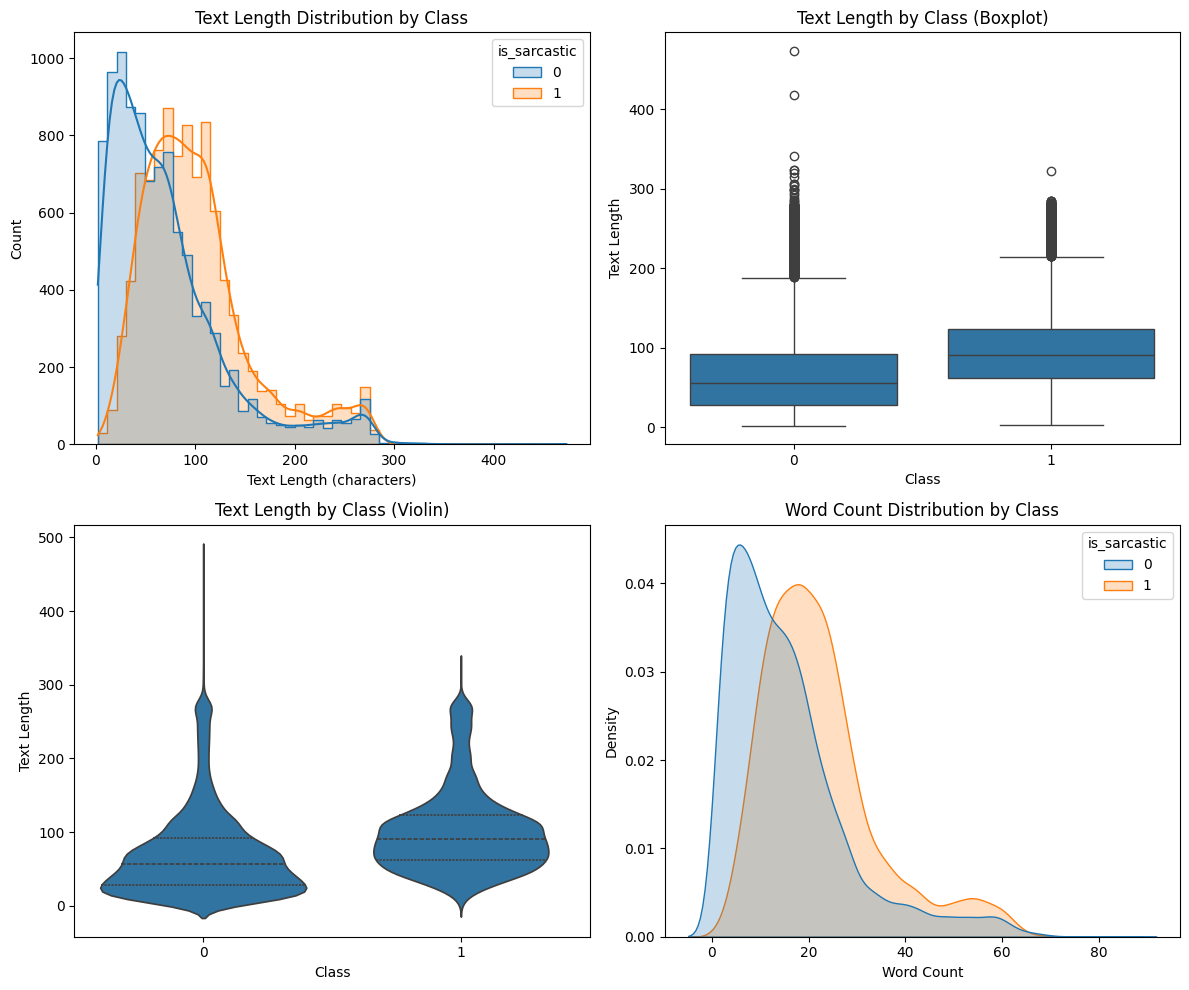

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming df1 has a text column 'text' and target column 'is_sarcastic'
df1['text_length'] = df1['text'].astype(str).str.len()
df1['word_count']  = df1['text'].astype(str).str.split().str.len()

# 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# --- Plot 1: Distribution (histogram + KDE) per class ---
sns.histplot(data=df1, x='text_length', hue='is_sarcastic',
             kde=True, bins=50, element='step', ax=axes[0, 0])
axes[0, 0].set_title('Text Length Distribution by Class')
axes[0, 0].set_xlabel('Text Length (characters)')

# --- Plot 2: Boxplot per class ---
sns.boxplot(data=df1, x='is_sarcastic', y='text_length', ax=axes[0, 1])
axes[0, 1].set_title('Text Length by Class (Boxplot)')
axes[0, 1].set_xlabel('Class')
axes[0, 1].set_ylabel('Text Length')

# --- Plot 3: Violin plot per class ---
sns.violinplot(data=df1, x='is_sarcastic', y='text_length',
               inner='quartile', ax=axes[1, 0])
axes[1, 0].set_title('Text Length by Class (Violin)')
axes[1, 0].set_xlabel('Class')
axes[1, 0].set_ylabel('Text Length')

# --- Plot 4: Word count distribution ---
sns.kdeplot(data=df1, x='word_count', hue='is_sarcastic',
            fill=True, common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title('Word Count Distribution by Class')
axes[1, 1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

#### Adding word-count feature

In [34]:
# Whitespace Splitting
# Splits by any whitespace (spaces, tabs, newlines).
# Works perfectly for both English and Urdu.
# ---------------------------------------------------------
df1['word_count'] = df1['text'].str.split().str.len().fillna(0).astype(int)

In [35]:
df1.head(2)

,is_sarcastic,text,<rolling_on_the_floor_laughing>,<face_with_tears_of_joy>,<neutral_face>,<folded_hands>,<smiling_face_with_sunglasses>,<beaming_face_with_smiling_eyes>,<broken_heart>,<fire>,...,<brain>,<ATM_sign>,<coin>,<money_bag>,<white_cane>,.,?,!,text_length,word_count
0,1,ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے,2,2,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,50,11
1,1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں,0,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,53,12


#### Downloading Corpus1

In [36]:
"""from google.colab import files

text1 = df1['text']

with open('corpus1.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(text1) + '\n')

# Trigger the browser download
files.download('corpus1.txt')"""

"from google.colab import files\n\ntext1 = df1['text']\n\nwith open('corpus1.txt', 'w', encoding='utf-8') as f:\n    f.write('\n'.join(text1) + '\n')\n\n# Trigger the browser download\nfiles.download('corpus1.txt')"

#### Downloading df1 as Dataset1

In [37]:
"""# Save the file first
df1.to_csv('dataset1.csv', index=False)

# Trigger the browser download
files.download('dataset1.csv')"""

"# Save the file first\ndf1.to_csv('dataset1.csv', index=False)\n\n# Trigger the browser download\nfiles.download('dataset1.csv')"

### ix. Dataset-2 (emojis demojized and only punctuations as a separate individual features)

Contains the following columns:

* `is_sarcastic`
* `word_count` - added after preprocessing
* `text`
  * contains no punctuation (the important ones are separated into their own columns)
  * contains demojized emojis i.e. laughing emoji converted into \<laughing emoji\> tag using `emoji` library

And the following three columns include the count of each element in a row:

* `!`
* `?`
* `.`

In [38]:
df2 = df.copy()

# Apply Punctuation extraction on the emoji-cleaned text (or original text)
df2["cleaned_text"], df2["punctuations"] = zip(
    *df2["text"].apply(text_preprocessing_pipeline)
)

# Dropping the uncleaned `text` column
df2.drop(columns='text', inplace=True)
# Renaming `cleaned_text` to `text`
df2 = df2.rename(columns={'cleaned_text': 'text'})

# adding a new feature "word-count"
df2['word_count'] = df2['text'].str.split().str.len().fillna(0).astype(int)

# output
df2.columns

Index(['is_sarcastic', 'text', 'punctuations', 'word_count'], dtype='object')

In [39]:
df2 = expand_element_counts(df2, 'punctuations')
df2.drop(columns=['punctuations'], inplace = True)
df2.columns

Index(['is_sarcastic', 'text', 'word_count', '.', '?', '!'], dtype='object')

In [40]:
df2.head(2)

,is_sarcastic,text,word_count,.,?,!
0,1,<rollingonthefloorlaughing> <facewithtearsofjoy> <facewithtearsofjoy> ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے <neutralface> <neutralface> <neutralface> <rollingonthefloorlaughing>,18,0,0,0
1,1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں <facewithtearsofjoy> <facewithtearsofjoy>,14,0,0,0


In [41]:
# Confirming that no hashtags are remaining

# Filter rows where the 'text' column contains a hashtag
hashtag_rows_df2 = df2[df2["text"].str.contains("#", na=False)]

# See how many rows have hashtags
print(f"Total rows with hashtags: {len(hashtag_rows_df2)}")

Total rows with hashtags: 0


#### Text-Length Statistics

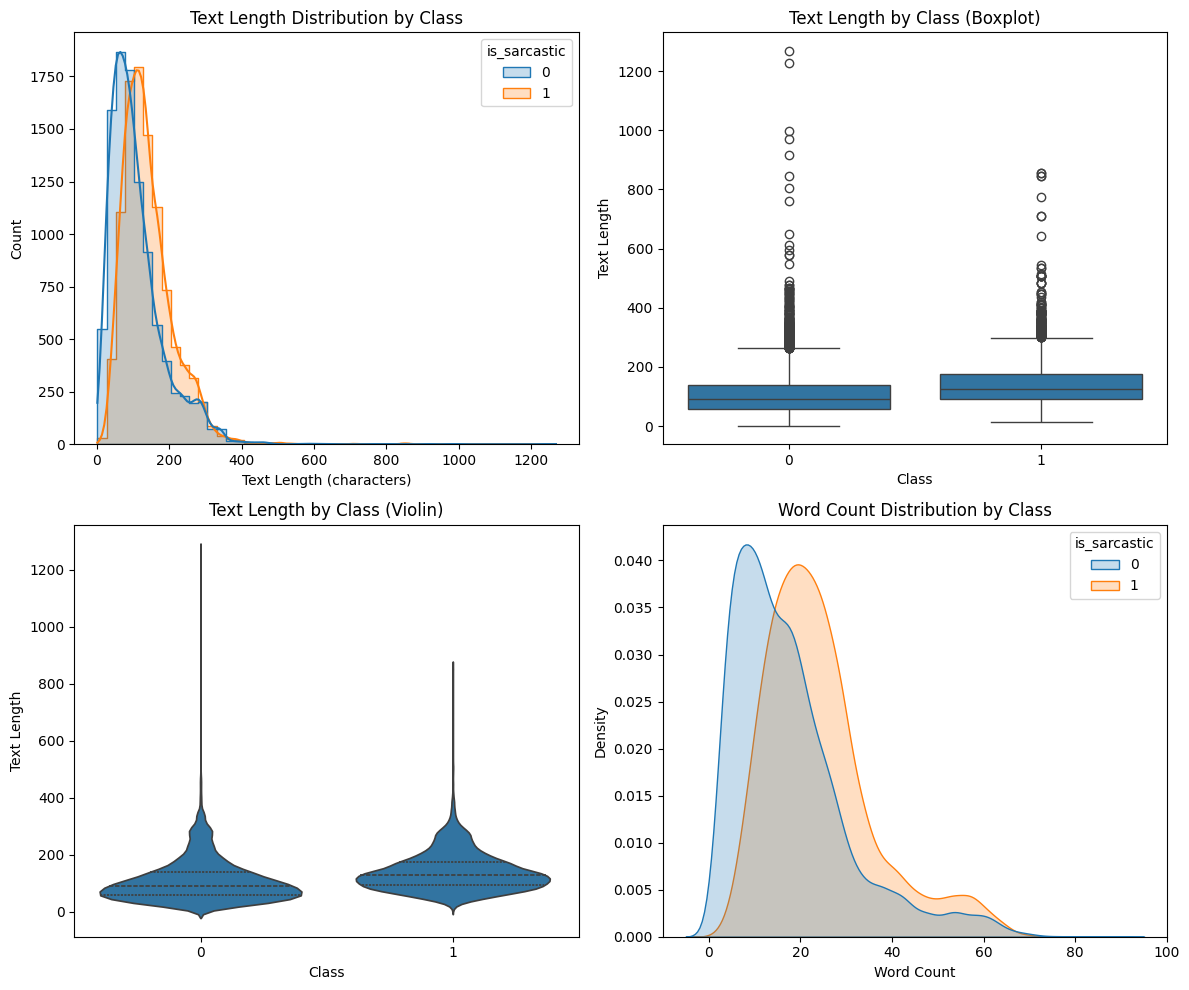

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming df2 has a text column 'text' and target column 'is_sarcastic'
df2['text_length'] = df2['text'].astype(str).str.len()
df2['word_count']  = df2['text'].astype(str).str.split().str.len()

# 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# --- Plot 1: Distribution (histogram + KDE) per class ---
sns.histplot(data=df2, x='text_length', hue='is_sarcastic',
             kde=True, bins=50, element='step', ax=axes[0, 0])
axes[0, 0].set_title('Text Length Distribution by Class')
axes[0, 0].set_xlabel('Text Length (characters)')

# --- Plot 2: Boxplot per class ---
sns.boxplot(data=df2, x='is_sarcastic', y='text_length', ax=axes[0, 1])
axes[0, 1].set_title('Text Length by Class (Boxplot)')
axes[0, 1].set_xlabel('Class')
axes[0, 1].set_ylabel('Text Length')

# --- Plot 3: Violin plot per class ---
sns.violinplot(data=df2, x='is_sarcastic', y='text_length',
               inner='quartile', ax=axes[1, 0])
axes[1, 0].set_title('Text Length by Class (Violin)')
axes[1, 0].set_xlabel('Class')
axes[1, 0].set_ylabel('Text Length')

# --- Plot 4: Word count distribution ---
sns.kdeplot(data=df2, x='word_count', hue='is_sarcastic',
            fill=True, common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title('Word Count Distribution by Class')
axes[1, 1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

#### Downloading Corpus2

In [43]:
"""text2 = df2['text']

with open('corpus2.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(text2) + '\n')

# Trigger the browser download
files.download('corpus2.txt')"""

"text2 = df2['text']\n\nwith open('corpus2.txt', 'w', encoding='utf-8') as f:\n    f.write('\n'.join(text2) + '\n')\n\n# Trigger the browser download\nfiles.download('corpus2.txt')"

#### Downloading df2 as Dataset2

In [44]:
"""# Save the file first
df2.to_csv('dataset2.csv', index=False)

# Trigger the browser download
files.download('dataset2.csv')"""

"# Save the file first\ndf2.to_csv('dataset2.csv', index=False)\n\n# Trigger the browser download\nfiles.download('dataset2.csv')"